In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sqlalchemy
import pymysql

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("Seaborn version:", sns.__version__)

print("\nAll required libraries imported successfully!")

Python version: 3.13.9
Pandas version: 2.3.3
NumPy version: 2.3.5
Matplotlib version: 3.10.6
Seaborn version: 0.13.2

All required libraries imported successfully!


In [2]:
from pathlib import Path

current_dir = Path.cwd()

possible_paths = [
    current_dir / "data" / "raw",
    current_dir.parent / "data" / "raw"
]

RAW_DIR = next(
    (path for path in possible_paths if path.exists()),
    None
)

if RAW_DIR is None:
    raise FileNotFoundError(
        "data/raw folder nahi mila. Current directory: "
        + str(current_dir)
    )

print("Notebook directory:", current_dir)
print("Raw data directory:", RAW_DIR)

Notebook directory: C:\Users\Dm692\OneDrive\Desktop\DataAnalyst\project\Python, PowerBi, SQL project\notebooks
Raw data directory: C:\Users\Dm692\OneDrive\Desktop\DataAnalyst\project\Python, PowerBi, SQL project\data\raw


In [3]:
required_files = [
    "olist_customers_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "product_category_name_translation.csv"
]

for filename in required_files:
    file_path = RAW_DIR / filename

    if file_path.exists():
        print(f"FOUND   : {filename}")
    else:
        print(f"MISSING : {filename}")

FOUND   : olist_customers_dataset.csv
FOUND   : olist_orders_dataset.csv
FOUND   : olist_order_items_dataset.csv
FOUND   : olist_order_payments_dataset.csv
FOUND   : olist_order_reviews_dataset.csv
FOUND   : olist_products_dataset.csv
FOUND   : olist_sellers_dataset.csv
FOUND   : olist_geolocation_dataset.csv
FOUND   : product_category_name_translation.csv


In [4]:
for filename in required_files:
    file_path = RAW_DIR / filename

    if file_path.exists():
        df_sample = pd.read_csv(file_path, nrows=5)

        print("\n" + "=" * 70)
        print("FILE:", filename)
        print("COLUMNS:", df_sample.columns.tolist())

        display(df_sample.head())


FILE: olist_customers_dataset.csv
COLUMNS: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP



FILE: olist_orders_dataset.csv
COLUMNS: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



FILE: olist_order_items_dataset.csv
COLUMNS: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


...

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP



FILE: olist_geolocation_dataset.csv
COLUMNS: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP



FILE: product_category_name_translation.csv
COLUMNS: ['product_category_name', 'product_category_name_english']


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [5]:

import pandas as pd
from pathlib import Path

# Har CSV ko uske filename ke basis par dictionary mein store karenge
dataframes = {}

for filename in required_files:
    file_path = RAW_DIR / filename

    dataframes[filename.replace(".csv", "")] = pd.read_csv(file_path)

print("Total datasets loaded:", len(dataframes))
print("\nDataset names:")

for name in dataframes:
    print(name)


Total datasets loaded: 9

Dataset names:
olist_customers_dataset
olist_orders_dataset
olist_order_items_dataset
olist_order_payments_dataset
olist_order_reviews_dataset
olist_products_dataset
olist_sellers_dataset
olist_geolocation_dataset
product_category_name_translation


In [6]:
for name, value in dataframes.items():
    print(f"{name} : {value.shape}")

olist_customers_dataset : (99441, 5)
olist_orders_dataset : (99441, 8)
olist_order_items_dataset : (112650, 7)
olist_order_payments_dataset : (103886, 5)
olist_order_reviews_dataset : (99224, 7)
olist_products_dataset : (32951, 9)
olist_sellers_dataset : (3095, 4)
olist_geolocation_dataset : (1000163, 5)
product_category_name_translation : (71, 2)


In [7]:

dataset_summary = pd.DataFrame([
    {
        "dataset": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / (1024**2), 2)
    }
    for name, df in dataframes.items()
])

display(
    dataset_summary.sort_values("rows", ascending=False)
    .reset_index(drop=True)
)


,dataset,rows,columns,memory_MB
0,olist_geolocation_dataset,1000163,5,129.38
1,olist_order_items_dataset,112650,7,35.99
2,olist_order_payments_dataset,103886,5,16.23
3,olist_customers_dataset,99441,5,26.59
4,olist_orders_dataset,99441,8,52.94
5,olist_order_reviews_dataset,99224,7,39.12
6,olist_products_dataset,32951,9,6.30
7,olist_sellers_dataset,3095,4,0.59
8,product_category_name_translation,71,2,0.01


In [8]:

missing_summary = []

for name, df in dataframes.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()

        missing_summary.append({
            "dataset": name,
            "column": column,
            "missing_count": int(missing_count),
            "missing_percent": round(
                df[column].isna().mean() * 100, 2
            )
        })

missing_df = pd.DataFrame(missing_summary)

display(
    missing_df[missing_df["missing_count"] > 0]
    .sort_values(
        ["missing_count", "missing_percent"],
        ascending=False
    )
    .reset_index(drop=True)
)


,dataset,column,missing_count,missing_percent
0,olist_order_reviews_dataset,review_comment_title,87656,88.34
1,olist_order_reviews_dataset,review_comment_message,58247,58.70
2,olist_orders_dataset,order_delivered_customer_date,2965,2.98
3,olist_orders_dataset,order_delivered_carrier_date,1783,1.79
4,olist_products_dataset,product_category_name,610,1.85
5,olist_products_dataset,product_name_lenght,610,1.85
6,olist_products_dataset,product_description_lenght,610,1.85
7,olist_products_dataset,product_photos_qty,610,1.85
8,olist_orders_dataset,order_approved_at,160,0.16
9,olist_products_dataset,product_weight_g,2,0.01


In [9]:

duplicate_summary = []

for name, df in dataframes.items():
    duplicate_summary.append({
        "dataset": name,
        "exact_duplicate_rows": int(df.duplicated().sum())
    })

duplicate_df = pd.DataFrame(duplicate_summary)

display(
    duplicate_df.sort_values(
        "exact_duplicate_rows",
        ascending=False
    ).reset_index(drop=True)
)


,dataset,exact_duplicate_rows
0,olist_geolocation_dataset,261831
1,olist_customers_dataset,0
2,olist_orders_dataset,0
3,olist_order_items_dataset,0
4,olist_order_payments_dataset,0
5,olist_order_reviews_dataset,0
6,olist_products_dataset,0
7,olist_sellers_dataset,0
8,product_category_name_translation,0


In [10]:

key_candidates = {
    "olist_customers_dataset": ["customer_id"],
    "olist_orders_dataset": ["order_id"],
    "olist_order_items_dataset": ["order_id", "order_item_id"],
    "olist_order_payments_dataset": ["order_id", "payment_sequential"],
    "olist_order_reviews_dataset": ["review_id"],
    "olist_products_dataset": ["product_id"],
    "olist_sellers_dataset": ["seller_id"],
    "product_category_name_translation": ["product_category_name"]
}

key_audit = []

for dataset_name, key_columns in key_candidates.items():
    df = dataframes[dataset_name]

    missing_keys = int(df[key_columns].isna().any(axis=1).sum())
    duplicate_keys = int(
        df.duplicated(subset=key_columns).sum()
    )

    key_audit.append({
        "dataset": dataset_name,
        "candidate_key": " + ".join(key_columns),
        "missing_key_rows": missing_keys,
        "duplicate_key_rows": duplicate_keys,
        "candidate_pass": (
            missing_keys == 0 and duplicate_keys == 0
        )
    })

key_audit_df = pd.DataFrame(key_audit)
display(key_audit_df)


,dataset,candidate_key,missing_key_rows,duplicate_key_rows,candidate_pass
0,olist_customers_dataset,customer_id,0,0,True
1,olist_orders_dataset,order_id,0,0,True
2,olist_order_items_dataset,order_id + order_item_id,0,0,True
3,olist_order_payments_dataset,order_id + payment_sequential,0,0,True
4,olist_order_reviews_dataset,review_id,0,814,False
5,olist_products_dataset,product_id,0,0,True
6,olist_sellers_dataset,seller_id,0,0,True
7,product_category_name_translation,product_category_name,0,0,True


In [11]:
reviews = dataframes["olist_order_reviews_dataset"]

duplicate_reviews = reviews[
    reviews.duplicated(subset=["review_id"], keep=False)
].sort_values("review_id")

print("Total rows involved in duplicate review IDs:",
      len(duplicate_reviews))

print("Unique duplicated review IDs:",
      duplicate_reviews["review_id"].nunique())

display(duplicate_reviews.head(20))

Total rows involved in duplicate review IDs: 1603
Unique duplicated review IDs: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [12]:
reviews = dataframes["olist_order_reviews_dataset"]

print("Total review rows:", len(reviews))
print("Unique review IDs:", reviews["review_id"].nunique())
print("Duplicate review ID rows:", reviews.duplicated(
    subset=["review_id"]
).sum())

print("\nSample rows with duplicated review IDs:")

duplicate_ids = reviews[
    reviews.duplicated(subset=["review_id"], keep=False)
].sort_values("review_id")

display(duplicate_ids.head(10))

Total review rows: 99224
Unique review IDs: 98410
Duplicate review ID rows: 814

Sample rows with duplicated review IDs:


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


In [13]:
reviews = dataframes["olist_order_reviews_dataset"]

print("Total rows:", len(reviews))
print("Unique review IDs:", reviews["review_id"].nunique())
print("Duplicate review ID rows:",
      reviews.duplicated(subset=["review_id"]).sum())

print("\nFirst 5 duplicate review ID records:")

duplicate_ids = reviews[
    reviews.duplicated(subset=["review_id"], keep=False)
].sort_values("review_id")

print(duplicate_ids.head(5).to_string(index=False))

Total rows: 99224
Unique review IDs: 98410
Duplicate review ID rows: 814

First 5 duplicate review ID records:
                       review_id                         order_id  review_score review_comment_title                                                                                                                                                                     review_comment_message review_creation_date review_answer_timestamp
00130cbe1f9d422698c812ed8ded1919 dfcdfc43867d1c1381bfaf62d6b9c195             1                  NaN O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.   2018-03-07 00:00:00     2018-03-20 18:08:23
00130cbe1f9d422698c812ed8ded1919 04a28263e085d399c97ae49e0b477efa             1                  NaN O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com a

In [14]:
reviews = dataframes["olist_order_reviews_dataset"]

print(
    "Exact duplicate rows:",
    reviews.duplicated().sum()
)

print(
    "Duplicate review IDs with different order IDs:",
    reviews.groupby("review_id")["order_id"].nunique()
           .gt(1).sum()
)

print(
    "Review IDs occurring more than once:",
    reviews["review_id"].value_counts().gt(1).sum()
)

Exact duplicate rows: 0
Duplicate review IDs with different order IDs: 789
Review IDs occurring more than once: 789


In [15]:
foreign_key_checks = [
    ("orders → customers",
     "olist_orders_dataset", "customer_id",
     "olist_customers_dataset", "customer_id"),

    ("items → orders",
     "olist_order_items_dataset", "order_id",
     "olist_orders_dataset", "order_id"),

    ("items → products",
     "olist_order_items_dataset", "product_id",
     "olist_products_dataset", "product_id"),

    ("items → sellers",
     "olist_order_items_dataset", "seller_id",
     "olist_sellers_dataset", "seller_id"),

    ("payments → orders",
     "olist_order_payments_dataset", "order_id",
     "olist_orders_dataset", "order_id"),

    ("reviews → orders",
     "olist_order_reviews_dataset", "order_id",
     "olist_orders_dataset", "order_id"),
]

fk_results = []

for relationship, child_name, child_col, parent_name, parent_col in foreign_key_checks:
    child = dataframes[child_name]
    parent = dataframes[parent_name]

    parent_values = set(parent[parent_col].dropna().unique())

    missing_parent = (
        child[child_col].notna()
        & ~child[child_col].isin(parent_values)
    )

    fk_results.append({
        "relationship": relationship,
        "child_rows": len(child),
        "null_foreign_keys": int(child[child_col].isna().sum()),
        "unmatched_foreign_keys": int(missing_parent.sum())
    })

fk_audit_df = pd.DataFrame(fk_results)
display(fk_audit_df)

,relationship,child_rows,null_foreign_keys,unmatched_foreign_keys
0,orders → customers,99441,0,0
1,items → orders,112650,0,0
2,items → products,112650,0,0
3,items → sellers,112650,0,0
4,payments → orders,103886,0,0
5,reviews → orders,99224,0,0


In [16]:
orders = dataframes["olist_orders_dataset"]

status_delivery_audit = (
    orders.groupby("order_status", dropna=False)
    .agg(
        total_orders=("order_id", "count"),
        missing_approval_date=("order_approved_at",
                               lambda s: s.isna().sum()),
        missing_carrier_date=("order_delivered_carrier_date",
                              lambda s: s.isna().sum()),
        missing_delivery_date=("order_delivered_customer_date",
                               lambda s: s.isna().sum())
    )
    .reset_index()
)

display(status_delivery_audit)

,order_status,total_orders,missing_approval_date,missing_carrier_date,missing_delivery_date
0,approved,2,0,2,2
1,canceled,625,141,550,619
2,created,5,5,5,5
3,delivered,96478,14,2,8
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,shipped,1107,0,0,1107
7,unavailable,609,0,609,609


In [17]:
orders = dataframes["olist_orders_dataset"]

print("Delivered orders with missing delivery date:")
display(
    orders[
        (orders["order_status"] == "delivered")
        & (orders["order_delivered_customer_date"].isna())
    ]
)

print("Shipped orders with delivery date:")
display(
    orders[
        (orders["order_status"] == "shipped")
        & (orders["order_delivered_customer_date"].notna())
    ].head(10)
)

Delivered orders with missing delivery date:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


Shipped orders with delivery date:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


In [18]:
orders = dataframes["olist_orders_dataset"]

print("Delivered orders with missing delivery date:",
      ((orders["order_status"] == "delivered") &
       (orders["order_delivered_customer_date"].isna())).sum())

print("Shipped orders with delivery date:",
      ((orders["order_status"] == "shipped") &
       (orders["order_delivered_customer_date"].notna())).sum())

print("\nShipped orders with delivery date — sample:")
display(
    orders.loc[
        (orders["order_status"] == "shipped") &
        (orders["order_delivered_customer_date"].notna()),
        ["order_id", "order_status",
         "order_delivered_carrier_date",
         "order_delivered_customer_date"]
    ].head(5)
)

Delivered orders with missing delivery date: 8
Shipped orders with delivery date: 0

Shipped orders with delivery date — sample:


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date


In [19]:
orders = dataframes["olist_orders_dataset"]

delivery_audit = (
    orders.assign(
        delivery_date_missing=
        orders["order_delivered_customer_date"].isna()
    )
    .groupby("order_status")
    .agg(
        total_orders=("order_id", "count"),
        missing_delivery_dates=("delivery_date_missing", "sum")
    )
    .reset_index()
)

delivery_audit["missing_percentage"] = (
    delivery_audit["missing_delivery_dates"]
    / delivery_audit["total_orders"] * 100
).round(2)

display(delivery_audit)

,order_status,total_orders,missing_delivery_dates,missing_percentage
0,approved,2,2,100.00
1,canceled,625,619,99.04
2,created,5,5,100.00
3,delivered,96478,8,0.01
4,invoiced,314,314,100.00
5,processing,301,301,100.00
6,shipped,1107,1107,100.00
7,unavailable,609,609,100.00


In [20]:
orders = dataframes["olist_orders_dataset"]

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

date_checks = {
    "approval_before_purchase": (
        orders["order_approved_at"]
        < orders["order_purchase_timestamp"]
    ),
    "carrier_before_purchase": (
        orders["order_delivered_carrier_date"]
        < orders["order_purchase_timestamp"]
    ),
    "delivery_before_carrier": (
        orders["order_delivered_customer_date"]
        < orders["order_delivered_carrier_date"]
    ),
    "delivery_before_purchase": (
        orders["order_delivered_customer_date"]
        < orders["order_purchase_timestamp"]
    )
}

for check_name, condition in date_checks.items():
    print(f"{check_name}: {int(condition.sum())}")

approval_before_purchase: 0
carrier_before_purchase: 166
delivery_before_carrier: 23
delivery_before_purchase: 0


In [21]:
orders = dataframes["olist_orders_dataset"]

carrier_before_purchase = orders[
    orders["order_delivered_carrier_date"].notna()
    & orders["order_purchase_timestamp"].notna()
    & (
        orders["order_delivered_carrier_date"]
        < orders["order_purchase_timestamp"]
    )
]

delivery_before_carrier = orders[
    orders["order_delivered_customer_date"].notna()
    & orders["order_delivered_carrier_date"].notna()
    & (
        orders["order_delivered_customer_date"]
        < orders["order_delivered_carrier_date"]
    )
]

print("Carrier before purchase:", len(carrier_before_purchase))
display(
    carrier_before_purchase[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].head(10)
)

print("\nDelivery before carrier:", len(delivery_before_carrier))
display(
    delivery_before_carrier[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_carrier_date",
            "order_delivered_customer_date"
        ]
    ].head(10)
)

Carrier before purchase: 166


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 13:27:00,2018-08-24 14:58:37
1111,ad133696906f6a78826daa0911b7daec,delivered,2018-06-15 15:41:22,2018-06-15 14:52:00,2018-06-22 18:09:37
1329,74e033208dc13a7b8127eb8e73d09b76,delivered,2018-05-02 10:48:44,2018-05-02 09:49:00,2018-05-07 23:06:36
1372,a6b58794fd2ba533359a76c08df576e3,delivered,2018-05-14 15:18:23,2018-05-14 13:46:00,2018-05-19 19:33:32
1864,5792e0b1c8c8a2bf53af468c9a422c88,delivered,2018-07-26 13:25:14,2018-07-26 12:42:00,2018-07-30 14:45:02
2760,c3eb293fd154223498b6551a728203e8,delivered,2018-07-19 14:06:04,2018-07-19 13:49:00,2018-07-24 19:35:36
3473,b0c2a7d04b165525254254a728c50a4e,delivered,2018-06-07 13:28:30,2018-06-07 13:22:00,2018-06-21 17:36:43
3661,2033a4586b5bec3229ebc1675a8ae092,delivered,2018-06-12 10:10:25,2018-06-12 10:09:00,2018-06-19 14:08:27
4114,08adcddad19d3acf37d1fa01cb9ded1e,delivered,2018-06-27 11:16:44,2018-06-27 10:57:00,2018-06-29 17:39:53
4159,dee6298ce7d1fb2645141ef9972157aa,shipped,2018-04-30 14:06:12,2018-04-30 12:59:00,NaT



Delivery before carrier: 23


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,delivered,2017-07-20 11:20:52,2017-07-28 16:57:58,2017-07-25 19:32:56
9553,383aa8b2724fe452d9ccd9934a8c628b,delivered,2017-07-02 20:58:43,2017-07-07 17:22:41,2017-07-06 14:27:51
13487,cb1134f9010d242e9515ad1c78ec0c39,delivered,2017-07-16 12:35:34,2017-07-20 19:22:02,2017-07-19 14:13:28
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-07-20 20:58:05,2017-08-01 18:23:30,2017-07-26 18:09:10
19268,5f9d46795c3126674e52becb3a1a517f,delivered,2017-07-18 11:48:20,2017-07-20 23:03:42,2017-07-20 18:52:41
21338,8c78d01de3a9009e23d6877a7cc9be20,delivered,2016-10-08 15:36:50,2016-10-26 11:41:53,2016-10-25 17:51:46
22520,b27af682321527a6349f1761eb3f360c,delivered,2017-06-14 20:17:04,2017-06-27 14:51:54,2017-06-26 15:45:35
25393,1cc3ae63caffff2d6c3ee3e78e074acf,delivered,2017-08-07 21:35:22,2017-08-10 18:28:56,2017-08-10 18:05:38
25646,e37f11cae9985ca58f0b56f268720537,delivered,2017-07-26 11:46:34,2017-08-01 18:17:47,2017-07-31 17:49:56
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-07-30 19:32:23,2017-08-09 18:18:43,2017-08-01 21:13:01


In [22]:
orders = dataframes["olist_orders_dataset"]

carrier_diff = (
    orders["order_delivered_carrier_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600

delivery_diff = (
    orders["order_delivered_customer_date"]
    - orders["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

print("Carrier date before purchase — difference in hours")
print(carrier_diff[carrier_diff < 0].describe().round(2))

print("\nDelivery date before carrier date — difference in hours")
print(delivery_diff[delivery_diff < 0].describe().round(2))

Carrier date before purchase — difference in hours
count     166.00
mean      -26.04
std       318.92
min     -4109.10
25%        -1.02
50%        -0.60
75%        -0.23
max        -0.01
dtype: float64

Delivery date before carrier date — difference in hours
count     23.00
mean     -78.46
std       89.31
min     -386.31
25%     -128.76
50%      -39.86
75%      -23.34
max       -0.39
dtype: float64


In [23]:
orders = dataframes["olist_orders_dataset"]

orders["carrier_purchase_diff_hours"] = (
    orders["order_delivered_carrier_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600

orders["delivery_carrier_diff_hours"] = (
    orders["order_delivered_customer_date"]
    - orders["order_delivered_carrier_date"]
).dt.total_seconds() / 3600

print("Top 5 carrier-before-purchase anomalies:")

display(
    orders.nsmallest(5, "carrier_purchase_diff_hours")[
        [
            "order_id",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_carrier_date",
            "carrier_purchase_diff_hours"
        ]
    ]
)

print("Top 5 delivery-before-carrier anomalies:")

display(
    orders.nsmallest(5, "delivery_carrier_diff_hours")[
        [
            "order_id",
            "order_status",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "delivery_carrier_diff_hours"
        ]
    ]
)

Top 5 carrier-before-purchase anomalies:


,order_id,order_status,order_purchase_timestamp,order_delivered_carrier_date,carrier_purchase_diff_hours
25883,7c48bb55e8e4f7e56d412e9653db37bc,delivered,2018-07-16 18:40:53,2018-01-26 13:35:00,-4109.098056
83321,4021cd7611d6d9ce5ffcd24817fc374f,delivered,2018-08-18 11:49:40,2018-08-14 06:22:00,-101.461111
67844,db090a16182b263b1e896bb26c6f66cf,delivered,2018-07-13 16:14:08,2018-07-13 13:59:00,-2.252222
65452,9711d975b961355b4b5d636857e48498,delivered,2018-06-13 15:23:50,2018-06-13 13:15:00,-2.147222
79401,89d32b64af005178b318f76cd60f2c3c,delivered,2018-07-06 11:54:40,2018-07-06 09:48:00,-2.111111


Top 5 delivery-before-carrier anomalies:


,order_id,order_status,order_delivered_carrier_date,order_delivered_customer_date,delivery_carrier_diff_hours
34939,c1e2bf2b7dd3309f2f5356c6b63968fa,delivered,2017-03-02 17:34:26,2017-02-14 15:15:57,-386.308056
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,delivered,2017-08-09 18:18:43,2017-08-01 21:13:01,-189.095000
45302,29941903985f944b0ffc49c479c1547d,delivered,2017-06-09 15:07:29,2017-06-02 11:09:16,-171.970278
14474,dceb62e8fa94b46006c9554fed743df0,delivered,2017-08-01 18:23:30,2017-07-26 18:09:10,-144.238889
49933,76458889992169d3135b264dc13aec67,delivered,2016-10-26 11:43:06,2016-10-20 18:03:17,-137.663611


In [24]:
orders = dataframes["olist_orders_dataset"]

carrier_before_purchase = (
    orders["order_delivered_carrier_date"]
    < orders["order_purchase_timestamp"]
)

delivery_before_carrier = (
    orders["order_delivered_customer_date"]
    < orders["order_delivered_carrier_date"]
)

print("Carrier before purchase:", carrier_before_purchase.sum())

print("Delivery before carrier:", delivery_before_carrier.sum())

print(
    "Orders having both anomalies:",
    (carrier_before_purchase & delivery_before_carrier).sum()
)

print(
    "Orders having either anomaly:",
    (carrier_before_purchase | delivery_before_carrier).sum()
)

Carrier before purchase: 166
Delivery before carrier: 23
Orders having both anomalies: 0
Orders having either anomaly: 189


### Date Consistency Audit — Findings

The order dataset was checked for chronological inconsistencies across purchase, carrier handover, and customer delivery timestamps.

**Findings:**
- 166 orders have a carrier handover timestamp earlier than the purchase timestamp.
- 23 orders have a customer delivery timestamp earlier than the carrier handover timestamp.
- No orders contain both types of anomalies.
- A total of 189 unique orders are affected.

**Data Quality Decision:**
These records are flagged as timestamp inconsistencies. No timestamps have been corrected or deleted because the correct values cannot be established confidently from the available data. Further investigation may be required before using these records for delivery-time analysis or predictive modeling.

In [25]:
orders = dataframes["olist_orders_dataset"]

print("Total orders:", len(orders))
print("Unique order IDs:", orders["order_id"].nunique())
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Missing order IDs:", orders["order_id"].isna().sum())
print("Missing customer IDs:", orders["customer_id"].isna().sum())

Total orders: 99441
Unique order IDs: 99441
Duplicate order IDs: 0
Missing order IDs: 0
Missing customer IDs: 0


In [26]:
orders = dataframes["olist_orders_dataset"]

status_summary = (
    orders["order_status"]
    .value_counts()
    .reset_index()
)

status_summary.columns = ["order_status", "order_count"]

status_summary["percentage"] = (
    status_summary["order_count"] / len(orders) * 100
).round(2)

display(status_summary)

,order_status,order_count,percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


In [27]:
payments = dataframes["olist_order_payments_dataset"]

payment_summary = (
    payments.groupby("payment_type")
    .agg(
        payment_records=("payment_type", "size"),
        total_payment_value=("payment_value", "sum"),
        average_payment_value=("payment_value", "mean")
    )
    .reset_index()
)

payment_summary["total_payment_value"] = (
    payment_summary["total_payment_value"].round(2)
)

payment_summary["average_payment_value"] = (
    payment_summary["average_payment_value"].round(2)
)

display(
    payment_summary.sort_values(
        "total_payment_value",
        ascending=False
    )
)

,payment_type,payment_records,total_payment_value,average_payment_value
1,credit_card,76795,12542084.19,163.32
0,boleto,19784,2869361.27,145.03
4,voucher,5775,379436.87,65.70
2,debit_card,1529,217989.79,142.57
3,not_defined,3,0.00,0.00


In [28]:
payments = dataframes["olist_order_payments_dataset"]

print("Total payment records:", len(payments))

print("\nMissing values:")
print(payments.isna().sum())

print("\nPayment value summary:")
print(payments["payment_value"].describe().round(2))

print("\nZero payment values:", (payments["payment_value"] == 0).sum())

print("Negative payment values:", (payments["payment_value"] < 0).sum())

Total payment records: 103886

Missing values:
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Payment value summary:
count    103886.00
mean        154.10
std         217.49
min           0.00
25%          56.79
50%         100.00
75%         171.84
max       13664.08
Name: payment_value, dtype: float64

Zero payment values: 9
Negative payment values: 0


In [29]:
payments = dataframes["olist_order_payments_dataset"]
orders = dataframes["olist_orders_dataset"]

zero_payments = payments[payments["payment_value"] == 0]

zero_payment_details = zero_payments.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

display(zero_payment_details)

print("\nZero payments by payment type:")
print(zero_payment_details["payment_type"].value_counts())

print("\nZero payments by order status:")
print(zero_payment_details["order_status"].value_counts())

,order_id,payment_sequential,payment_type,payment_installments,payment_value,order_status
0,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0,delivered
1,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0,shipped
2,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0,delivered
3,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0,canceled
4,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0,canceled
5,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0,delivered
6,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0,shipped
7,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0,canceled
8,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0,delivered



Zero payments by payment type:
payment_type
voucher        6
not_defined    3
Name: count, dtype: int64

Zero payments by order status:
order_status
delivered    4
canceled     3
shipped      2
Name: count, dtype: int64


In [30]:
payments = dataframes["olist_order_payments_dataset"]
orders = dataframes["olist_orders_dataset"]

order_payment_summary = (
    payments.groupby("order_id")
    .agg(
        payment_records=("payment_value", "size"),
        total_payment_value=("payment_value", "sum"),
        zero_payment_records=("payment_value", lambda x: (x == 0).sum())
    )
    .reset_index()
)

zero_payment_orders = (
    payments.loc[payments["payment_value"] == 0, ["order_id"]]
    .drop_duplicates()
    .merge(order_payment_summary, on="order_id", how="left")
    .merge(
        orders[["order_id", "order_status"]],
        on="order_id",
        how="left"
    )
)

display(zero_payment_orders.sort_values("order_id"))

,order_id,payment_records,total_payment_value,zero_payment_records,order_status
4,00b1cb0320190ca0daa2c88b35206009,1,0.00,1,canceled
5,45ed6e85398a87c253db47c2d9f48216,3,71.14,1,delivered
3,4637ca194b6387e2d538dc89b124b0ee,1,0.00,1,canceled
2,6ccb433e00daae1283ccc956189c82ae,4,122.04,1,delivered
0,8bcbe01d44d147f901cd3192671144db,4,74.16,1,delivered
7,b23878b3e8eb4d25a158f57d96331b18,4,171.57,1,delivered
6,c8c528189310eaa44a745b8d9d26908b,1,0.00,1,canceled
1,fa65dad1b0e818e3ccc5cb0e39231352,29,457.99,2,shipped


In [31]:
items = dataframes["olist_order_items_dataset"]

print("Total order-item records:", len(items))

print("\nMissing values:")
print(items.isna().sum())

print("\nExact duplicate rows:", items.duplicated().sum())

print("\nPrice summary:")
print(items["price"].describe().round(2))

print("\nFreight value summary:")
print(items["freight_value"].describe().round(2))

print("\nZero or negative prices:", (items["price"] <= 0).sum())

print("Negative freight values:", (items["freight_value"] < 0).sum())

Total order-item records: 112650

Missing values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Exact duplicate rows: 0

Price summary:
count    112650.00
mean        120.65
std         183.63
min           0.85
25%          39.90
50%          74.99
75%         134.90
max        6735.00
Name: price, dtype: float64

Freight value summary:
count    112650.00
mean         19.99
std          15.81
min           0.00
25%          13.08
50%          16.26
75%          21.15
max         409.68
Name: freight_value, dtype: float64

Zero or negative prices: 0
Negative freight values: 0


In [32]:
items = dataframes["olist_order_items_dataset"]

print("Unique orders in order items:", items["order_id"].nunique())

print(
    "Duplicate order_id + order_item_id combinations:",
    items.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

items_per_order = items.groupby("order_id").size()

print("\nItems per order summary:")
print(items_per_order.describe().round(2))

print("\nOrders with maximum items:")
print(items_per_order.sort_values(ascending=False).head(10))

Unique orders in order items: 98666
Duplicate order_id + order_item_id combinations: 0

Items per order summary:
count    98666.00
mean         1.14
std          0.54
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         21.00
dtype: float64

Orders with maximum items:
order_id
8272b63d03f5f79c56e9e4120aec44ef    21
1b15974a0141d54e36626dca3fdc731a    20
ab14fdcfbe524636d65ee38360e22ce8    20
9ef13efd6949e4573a18964dd1bbe7f5    15
428a2f660dc84138d969ccd69a0ab6d5    15
9bdc4d4c71aa1de4606060929dee888c    14
73c8ab38f07dc94389065f7eba4f297a    14
37ee401157a3a0b28c9c6d0ed8c3b24b    13
2c2a19b5703863c908512d135aa6accc    12
c05d6a79e55da72ca780ce90364abed9    12
dtype: int64


In [33]:
items = dataframes["olist_order_items_dataset"]

print("Total item price:", round(items["price"].sum(), 2))
print("Total freight value:", round(items["freight_value"].sum(), 2))

print("\nTop 10 highest-priced items:")
display(
    items.nlargest(10, "price")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

print("\nTop 10 highest-freight items:")
display(
    items.nlargest(10, "freight_value")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

Total item price: 13591643.7
Total freight value: 2251909.54

Top 10 highest-priced items:


,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01



Top 10 highest-freight items:


,order_id,product_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,1045.00,314.40


In [34]:

items = dataframes["olist_order_items_dataset"]
products = dataframes["olist_products_dataset"]
sellers = dataframes["olist_sellers_dataset"]

# Product coverage
print("Unique products in items:", items["product_id"].nunique())
print("Unique products in products table:", products["product_id"].nunique())

# Seller coverage
print("\nUnique sellers in items:", items["seller_id"].nunique())
print("Unique sellers in sellers table:", sellers["seller_id"].nunique())

# Products sold by multiple sellers
product_seller_counts = (
    items.groupby("product_id")["seller_id"]
    .nunique()
)

print(
    "\nProducts sold by multiple sellers:",
    (product_seller_counts > 1).sum()
)

# Sellers with the most order-item records
seller_item_counts = (
    items.groupby("seller_id")
    .size()
    .sort_values(ascending=False)
)

print("\nTop 10 sellers by item records:")
display(seller_item_counts.head(10))


Unique products in items: 32951
Unique products in products table: 32951

Unique sellers in items: 3095
Unique sellers in sellers table: 3095

Products sold by multiple sellers: 1225

Top 10 sellers by item records:


seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
dtype: int64

## Order Items Dataset — Validation Findings

### 1. Data Quality
- Total records: 112,650
- Missing values: None
- Exact duplicate rows: 0
- Zero or negative item prices: 0
- Negative freight values: 0

### 2. Order-Level Structure
- Unique orders represented: 98,666
- Duplicate `(order_id, order_item_id)` combinations: 0
- Average items per order: 1.14
- Maximum items in a single order: 21

### 3. Price and Freight Analysis
- Total item price: 13,591,643.70
- Total freight value: 2,251,909.54
- Maximum item price: 6,735.00
- Maximum freight value: 409.68

These totals represent sums from the order-items dataset and should not automatically be treated as net revenue or total customer payments.

### 4. Product and Seller Relationships
- Distinct products in order items: 32,951
- Products in products master table: 32,951
- Distinct sellers in order items: 3,095
- Sellers in sellers master table: 3,095
- Products associated with multiple sellers: 1,225

### 5. Preliminary Conclusion
The order-items dataset has no missing values or exact duplicate rows. The tested order-item combination is unique, and product and seller counts match their respective master tables. High prices and freight values will be retained until further analysis establishes whether they are genuine or anomalous.


In [35]:

items = dataframes["olist_order_items_dataset"]
payments = dataframes["olist_order_payments_dataset"]

# Calculate item totals for each order
item_totals = (
    items.groupby("order_id")
    .agg(item_total=("price", "sum"))
    .reset_index()
)

# Calculate payment totals for each order
payment_totals = (
    payments.groupby("order_id")
    .agg(payment_total=("payment_value", "sum"))
    .reset_index()
)

# Compare both totals
comparison = item_totals.merge(
    payment_totals,
    on="order_id",
    how="outer",
    indicator=True
)

comparison["difference"] = (
    comparison["payment_total"] - comparison["item_total"]
)

print("Orders in comparison:", len(comparison))
print("\nMerge status:")
print(comparison["_merge"].value_counts())

print("\nDifference summary:")
print(comparison["difference"].describe().round(2))

print("\nOrders missing item or payment totals:")
display(comparison[comparison["_merge"] != "both"].head(10))


Orders in comparison: 99441

Merge status:
_merge
both          98665
right_only      775
left_only         1
Name: count, dtype: int64

Difference summary:
count    98665.00
mean        22.85
std         21.71
min         -5.17
25%         13.86
50%         17.19
75%         24.09
max       1794.96
Name: difference, dtype: float64

Orders missing item or payment totals:


,order_id,item_total,payment_total,_merge,difference
24,0010dedd556712d7bb69a19cb7bbd37a,NaN,111.12,right_only,NaN
229,00a500bc03bc4ec968e574c2553bed4b,NaN,555.99,right_only,NaN
251,00b1cb0320190ca0daa2c88b35206009,NaN,0.00,right_only,NaN
271,00bca4adac549020c1273714d04d0208,NaN,111.30,right_only,NaN
309,00d0ffd14774da775ac832ba8520510f,NaN,134.49,right_only,NaN
324,00daac8efd71674d62356c2a306d1e4c,NaN,67.97,right_only,NaN
466,0130f0f71fb0e831d18e6a3b33a3a50c,NaN,52.77,right_only,NaN
532,016706d732e79b49035275c048edb2c4,NaN,65.00,right_only,NaN
692,01cb6d702e5233235f4125309d184bf4,NaN,94.21,right_only,NaN
1056,02bfe71c2bbd56f6de9c2c357adff45c,NaN,137.32,right_only,NaN


In [36]:

orders = dataframes["olist_orders_dataset"]

# Add order status to the comparison
comparison_status = comparison.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

# Check missing item/payment records by order status
status_audit = (
    comparison_status
    .groupby(["_merge", "order_status"])
    .size()
    .reset_index(name="order_count")
    .sort_values(["_merge", "order_count"], ascending=[True, False])
)

print("Missing item/payment records by order status:")
display(status_audit)

# Inspect orders that have payment records but no item records
payment_without_items = comparison_status[
    comparison_status["_merge"] == "right_only"
]

print("\nPayment records without item records:")
print("Total orders:", len(payment_without_items))

display(
    payment_without_items[
        ["order_id", "order_status", "payment_total"]
    ].head(15)
)

# Inspect the order that has items but no payment record
items_without_payment = comparison_status[
    comparison_status["_merge"] == "left_only"
]

print("\nItem records without payment records:")
display(
    items_without_payment[
        ["order_id", "order_status", "item_total"]
    ]
)


Missing item/payment records by order status:


C:\Users\Dm692\AppData\Local\Temp\ipykernel_19508\695316750.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["_merge", "order_status"])


,_merge,order_status,order_count
3,left_only,delivered,1
0,left_only,approved,0
1,left_only,canceled,0
2,left_only,created,0
4,left_only,invoiced,0
5,left_only,processing,0
6,left_only,shipped,0
7,left_only,unavailable,0
15,right_only,unavailable,603
9,right_only,canceled,164



Payment records without item records:
Total orders: 775


,order_id,order_status,payment_total
24,0010dedd556712d7bb69a19cb7bbd37a,unavailable,111.12
229,00a500bc03bc4ec968e574c2553bed4b,unavailable,555.99
251,00b1cb0320190ca0daa2c88b35206009,canceled,0.00
271,00bca4adac549020c1273714d04d0208,unavailable,111.30
309,00d0ffd14774da775ac832ba8520510f,canceled,134.49
324,00daac8efd71674d62356c2a306d1e4c,unavailable,67.97
466,0130f0f71fb0e831d18e6a3b33a3a50c,unavailable,52.77
532,016706d732e79b49035275c048edb2c4,unavailable,65.00
692,01cb6d702e5233235f4125309d184bf4,unavailable,94.21
1056,02bfe71c2bbd56f6de9c2c357adff45c,unavailable,137.32



Item records without payment records:


,order_id,order_status,item_total
74448,bfbd0f9bdef84302105ad712db648a6c,delivered,134.97


In [37]:

payments = dataframes["olist_order_payments_dataset"]

# Only orders that have payment records but no item records
payment_only_ids = payment_without_items["order_id"]

payment_only_details = payments[
    payments["order_id"].isin(payment_only_ids)
].merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

status_payment_summary = (
    payment_only_details.groupby("order_status")
    .agg(
        payment_records=("payment_value", "size"),
        unique_orders=("order_id", "nunique"),
        total_payment_value=("payment_value", "sum"),
        zero_payment_records=(
            "payment_value",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)

status_payment_summary["total_payment_value"] = (
    status_payment_summary["total_payment_value"].round(2)
)

display(
    status_payment_summary.sort_values(
        "unique_orders", ascending=False
    )
)

# Inspect the one delivered order with items but no payment
print("\nDelivered order without payment record:")
display(
    items_without_payment.merge(
        orders,
        on=["order_id", "order_status"],
        how="left"
    )
)


,order_status,payment_records,unique_orders,total_payment_value,zero_payment_records
4,unavailable,643,603,124339.02,0
0,canceled,179,164,37337.87,3
1,created,5,5,688.10,0
2,invoiced,2,2,149.23,0
3,shipped,1,1,77.73,0



Delivered order without payment record:


,order_id,item_total,payment_total,_merge,difference,order_status,customer_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,carrier_purchase_diff_hours,delivery_carrier_diff_hours
0,bfbd0f9bdef84302105ad712db648a6c,134.97,NaN,left_only,NaN,delivered,86dc2ffce2dfff336de2f386a786e574,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,1276.920833,38.595833


In [38]:

customers = dataframes["olist_customers_dataset"]
reviews = dataframes["olist_order_reviews_dataset"]

print("CUSTOMER AUDIT")
print("Total customer records:", len(customers))
print("Unique customer IDs:", customers["customer_id"].nunique())
print("Unique customer unique IDs:", customers["customer_unique_id"].nunique())
print("Customers with repeated customer_unique_id:",
      customers["customer_unique_id"].duplicated().sum())

print("\nREVIEW AUDIT")
print("Total review records:", len(reviews))
print("Unique review scores:", sorted(reviews["review_score"].dropna().unique()))
print("\nReview score distribution:")
display(
    reviews["review_score"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="review_count")
)

print("\nMissing review scores:", reviews["review_score"].isna().sum())
print("Missing review IDs:", reviews["review_id"].isna().sum())
print("Missing review order IDs:", reviews["order_id"].isna().sum())


CUSTOMER AUDIT
Total customer records: 99441
Unique customer IDs: 99441
Unique customer unique IDs: 96096
Customers with repeated customer_unique_id: 3345

REVIEW AUDIT
Total review records: 99224
Unique review scores: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Review score distribution:


,review_score,review_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328



Missing review scores: 0
Missing review IDs: 0
Missing review order IDs: 0


In [39]:

customers = dataframes["olist_customers_dataset"]
orders = dataframes["olist_orders_dataset"]

# Number of customer records per unique customer
customer_record_counts = (
    customers.groupby("customer_unique_id")["customer_id"]
    .nunique()
)

print("Unique customers:", customer_record_counts.size)
print("Customers with one customer_id:",
      (customer_record_counts == 1).sum())
print("Customers with multiple customer_ids:",
      (customer_record_counts > 1).sum())

print("\nCustomer records per unique customer:")
print(customer_record_counts.describe().round(2))

# Link customer identity to orders
customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

orders_per_customer = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
)

print("\nOrders per unique customer:")
print(orders_per_customer.describe().round(2))

print("Customers with more than one order:",
      (orders_per_customer > 1).sum())


Unique customers: 96096
Customers with one customer_id: 93099
Customers with multiple customer_ids: 2997

Customer records per unique customer:
count    96096.00
mean         1.03
std          0.21
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         17.00
Name: customer_id, dtype: float64

Orders per unique customer:
count    96096.00
mean         1.03
std          0.21
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         17.00
Name: order_id, dtype: float64
Customers with more than one order: 2997


In [40]:

products = dataframes["olist_products_dataset"]
translation = dataframes["product_category_name_translation"]

print("PRODUCT AUDIT")
print("Total products:", len(products))
print("Unique product IDs:", products["product_id"].nunique())

print("\nMissing values by product column:")
display(
    products.isna().sum()
    .rename("missing_count")
    .to_frame()
    .query("missing_count > 0")
)

print("\nProducts with missing category:",
      products["product_category_name"].isna().sum())

print("\nCATEGORY TRANSLATION AUDIT")
print("Translation rows:", len(translation))
print("Unique source categories:",
      translation["product_category_name"].nunique())
print("Unique English categories:",
      translation["product_category_name_english"].nunique())

# Categories present in products but absent from translation
product_categories = set(
    products["product_category_name"].dropna().unique()
)

translated_categories = set(
    translation["product_category_name"].dropna().unique()
)

untranslated_categories = product_categories - translated_categories

print("\nProduct categories without translation:",
      len(untranslated_categories))
print(sorted(untranslated_categories)[:20])


PRODUCT AUDIT
Total products: 32951
Unique product IDs: 32951

Missing values by product column:


,missing_count
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2



Products with missing category: 610

CATEGORY TRANSLATION AUDIT
Translation rows: 71
Unique source categories: 71
Unique English categories: 71

Product categories without translation: 2
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


In [41]:

metadata_cols = [
    "product_category_name",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

print("Products missing all 4 metadata fields:",
      products[metadata_cols].isna().all(axis=1).sum())

print("Products missing at least one metadata field:",
      products[metadata_cols].isna().any(axis=1).sum())

print("\nProducts with missing physical attributes:")
physical_cols = [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]

print(
    products[physical_cols].isna().any(axis=1).sum()
)


Products missing all 4 metadata fields: 610
Products missing at least one metadata field: 610

Products with missing physical attributes:
2


In [42]:

sellers = dataframes["olist_sellers_dataset"]
geolocation = dataframes["olist_geolocation_dataset"]

print("SELLER AUDIT")
print("Total seller records:", len(sellers))
print("Unique seller IDs:", sellers["seller_id"].nunique())

print("\nMissing values in sellers:")
display(
    sellers.isna().sum()
    .rename("missing_count")
    .to_frame()
    .query("missing_count > 0")
)

print("\nGEOLOCATION AUDIT")
print("Total records:", len(geolocation))
print("Exact duplicate rows:", geolocation.duplicated().sum())

print("\nMissing values in geolocation:")
display(
    geolocation.isna().sum()
    .rename("missing_count")
    .to_frame()
    .query("missing_count > 0")
)

print("\nUnique postal prefixes:",
      geolocation["geolocation_zip_code_prefix"].nunique())

print("Unique latitude-longitude pairs:",
      geolocation[
          ["geolocation_lat", "geolocation_lng"]
      ].drop_duplicates().shape[0])


SELLER AUDIT
Total seller records: 3095
Unique seller IDs: 3095

Missing values in sellers:


,missing_count



GEOLOCATION AUDIT
Total records: 1000163
Exact duplicate rows: 261831

Missing values in geolocation:


,missing_count



Unique postal prefixes: 19015
Unique latitude-longitude pairs: 718463


In [43]:

# Count coordinate pairs for each postal prefix
coordinates_per_prefix = (
    geolocation.groupby("geolocation_zip_code_prefix")[
        ["geolocation_lat", "geolocation_lng"]
    ]
    .apply(lambda group: group.drop_duplicates().shape[0])
)

print("Postal prefixes:", len(coordinates_per_prefix))

print("\nCoordinate points per postal prefix:")
print(coordinates_per_prefix.describe().round(2))

print("\nPrefixes with more than one coordinate pair:",
      (coordinates_per_prefix > 1).sum())

print("\nPrefixes with more than 10 coordinate pairs:",
      (coordinates_per_prefix > 10).sum())

print("\nFive prefixes with the most coordinate pairs:")
print(coordinates_per_prefix.sort_values(ascending=False).head())


Postal prefixes: 19015

Coordinate points per postal prefix:
count    19015.00
mean        37.87
std         50.00
min          1.00
25%          8.00
50%         22.00
75%         48.00
max        746.00
dtype: float64

Prefixes with more than one coordinate pair: 17781

Prefixes with more than 10 coordinate pairs: 13340

Five prefixes with the most coordinate pairs:
geolocation_zip_code_prefix
38400    746
11680    727
35500    726
11740    666
36400    627
dtype: int64


In [44]:

# Check product categories without English translations
translation = dataframes["product_category_name_translation"]

product_categories = set(
    dataframes["olist_products_dataset"]
    ["product_category_name"]
    .dropna()
    .unique()
)

translated_categories = set(
    translation["product_category_name"]
    .dropna()
    .unique()
)

untranslated_categories = sorted(
    product_categories - translated_categories
)

print("Untranslated categories:", untranslated_categories)

# Check translation rows with missing English names
print(
    "\nMissing English category translations:",
    translation["product_category_name_english"].isna().sum()
)

# Check whether every translated source category exists in products
unused_translation_categories = sorted(
    translated_categories - product_categories
)

print(
    "\nTranslation categories absent from products:",
    unused_translation_categories
)


Untranslated categories: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

Missing English category translations: 0

Translation categories absent from products: []


# Phase 2: Data Quality Audit — Findings & Cleaning Decisions

## 1. Project Overview

The Olist E-Commerce dataset contains nine related CSV files covering customers, orders, order items, payments, reviews, products, sellers, geolocation, and product category translations.

The initial audit identified missing values, duplicate records, review-ID anomalies, order timestamp inconsistencies, payment reconciliation differences, and incomplete category translations.

No original CSV files have been modified during this audit.

## 2. Key Findings

### Customers
- 99,441 customer records and 96,096 unique customers.
- 2,997 unique customers have multiple customer IDs and more than one order.
- `customer_unique_id` should be used for customer-level aggregation.

### Orders
- 96,478 orders have delivered status.
- Some orders have missing timestamps or inconsistent delivery-related timestamps.
- Six canceled orders have a delivery timestamp and require further investigation.

### Order Items
- 112,650 records with no missing values or exact duplicate rows.
- The composite key (`order_id`, `order_item_id`) is unique.
- Total item price: 13,591,643.70.
- Total freight value: 2,251,909.54.

### Payments
- 103,886 payment records with no missing values.
- Nine zero-value payment records exist across eight orders.
- One delivered order has item records but no payment record.
- Some orders have payment records but no item records.
- Payment totals and item-price totals differ; freight, payment structure, and order status must be considered before classifying differences as errors.

### Reviews
- 99,224 review records with scores from 1 to 5.
- Review IDs are not unique: 814 rows have repeated review IDs.
- Review comments contain many missing values; these are not automatically data errors.

### Products
- 32,951 unique products.
- 610 products have all four of these fields missing: category, name length, description length, and photo quantity.
- Two products have missing physical attributes.

### Sellers
- 3,095 seller records with unique seller IDs and no missing values.

### Geolocation
- 1,000,163 records and 261,831 exact duplicate rows.
- 19,015 unique postal prefixes.
- Many postal prefixes contain multiple coordinate pairs; different coordinates must not be treated as exact duplicates.

### Category Translation
- 71 translation records with no missing English category names.
- Two product categories are not translated: `pc_gamer` and `portateis_cozinha_e_preparadores_de_alimentos`.

## 3. Planned Cleaning Decisions

1. Preserve the original CSV files and perform cleaning on working copies.
2. Investigate repeated review IDs before deciding how reviews should be modeled.
3. Retain missing review comments as missing; do not discard reviews simply because comments are absent.
4. Investigate unusual order timestamps and canceled orders with delivery timestamps before deciding how to handle them.
5. Investigate zero-value payment records and unmatched payment/item orders before excluding any records.
6. Investigate the 610 products with missing metadata; avoid deleting them automatically.
7. Keep untranslated categories until a verified mapping is available.
8. For geolocation, consider removing exact duplicate rows in a separate working table while preserving distinct

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the existing raw datasets
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"

orders = pd.read_csv(
    RAW_DATA_PATH / "olist_orders_dataset.csv"
)

order_items = pd.read_csv(
    RAW_DATA_PATH / "olist_order_items_dataset.csv"
)

print("Orders shape:", orders.shape)
print("Order items shape:", order_items.shape)

orders.head()


Orders shape: (99441, 8)
Order items shape: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [46]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print(orders[date_columns].dtypes)
print(orders[date_columns].isna().sum())

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [47]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [48]:

# Extract year and month from purchase timestamp
orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M")
)

# Count orders placed each month
monthly_orders = (
    orders.groupby("order_month")["order_id"]
    .nunique()
    .reset_index(name="total_orders")
)

monthly_orders["order_month"] = (
    monthly_orders["order_month"].astype(str)
)

print(monthly_orders.head())
print("\nTotal months:", len(monthly_orders))


  order_month  total_orders
0     2016-09             4
1     2016-10           324
2     2016-12             1
3     2017-01           800
4     2017-02          1780

Total months: 25


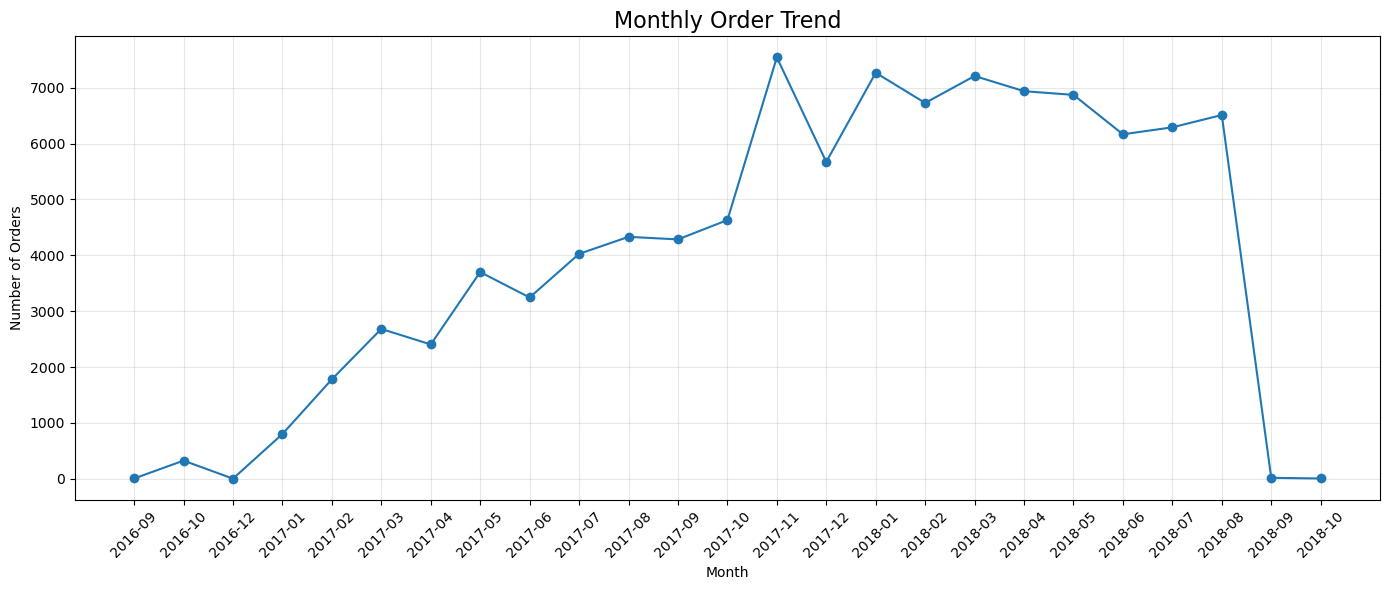

In [49]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders["order_month"],
    monthly_orders["total_orders"],
    marker="o"
)

plt.title("Monthly Order Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [50]:

print("First purchase date:",
      orders["order_purchase_timestamp"].min())

print("Last purchase date:",
      orders["order_purchase_timestamp"].max())

print("\nOrders in the last 3 months:")
print(
    orders.groupby(
        orders["order_purchase_timestamp"].dt.to_period("M")
    )["order_id"]
    .nunique()
    .tail(3)
)


First purchase date: 2016-09-04 21:15:19
Last purchase date: 2018-10-17 17:30:18

Orders in the last 3 months:
order_purchase_timestamp
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64


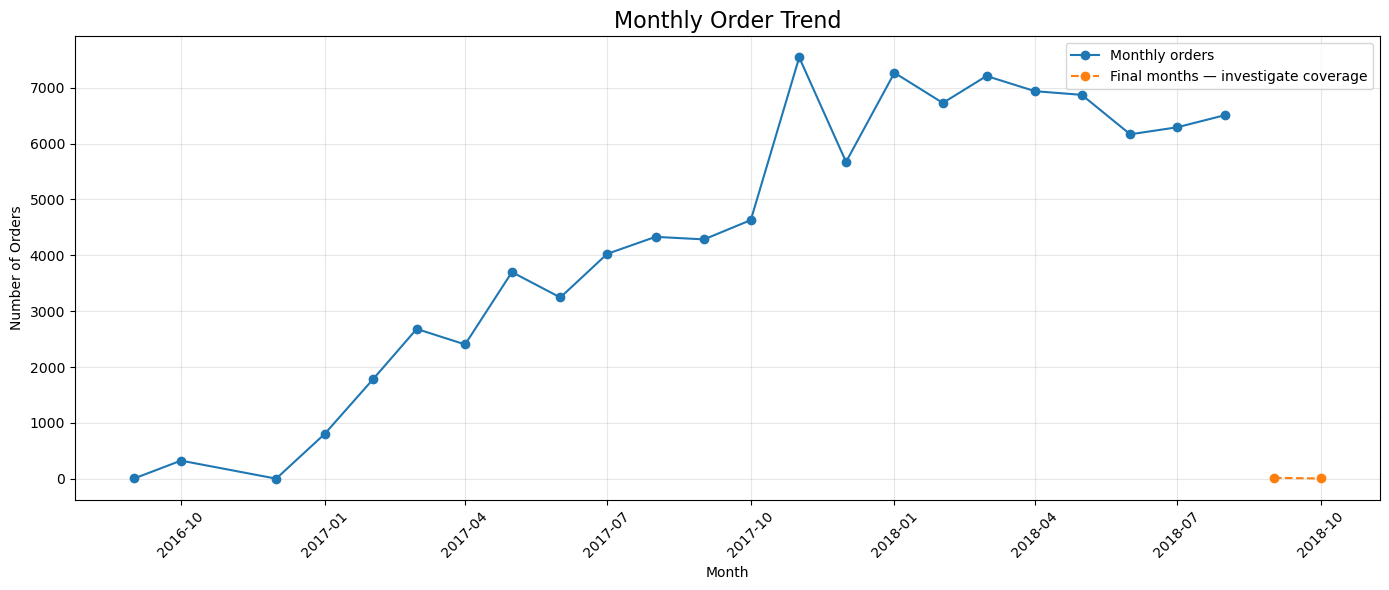

In [51]:

monthly_orders["order_month"] = pd.to_datetime(
    monthly_orders["order_month"]
)

# Separate regular months and low-volume final months
incomplete_months = monthly_orders["order_month"] >= "2018-09-01"

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders.loc[~incomplete_months, "order_month"],
    monthly_orders.loc[~incomplete_months, "total_orders"],
    marker="o",
    label="Monthly orders"
)

plt.plot(
    monthly_orders.loc[incomplete_months, "order_month"],
    monthly_orders.loc[incomplete_months, "total_orders"],
    marker="o",
    linestyle="--",
    label="Final months — investigate coverage"
)

plt.title("Monthly Order Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [52]:

# Calculate total item sales for each order
order_sales = (
    order_items.groupby("order_id")["price"]
    .sum()
    .reset_index(name="item_sales")
)

# Add order purchase dates
sales_data = orders[
    ["order_id", "order_purchase_timestamp"]
].merge(
    order_sales,
    on="order_id",
    how="left"
)

# Aggregate item sales by month
sales_data["order_month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_sales = (
    sales_data.groupby("order_month")["item_sales"]
    .sum()
    .reset_index(name="total_item_sales")
)

monthly_sales["order_month"] = (
    monthly_sales["order_month"].astype(str)
)

print(monthly_sales.head())
print("\nTotal item sales:", round(sales_data["item_sales"].sum(), 2))


  order_month  total_item_sales
0     2016-09            267.36
1     2016-10          49507.66
2     2016-12             10.90
3     2017-01         120312.87
4     2017-02         247303.02

Total item sales: 13591643.7


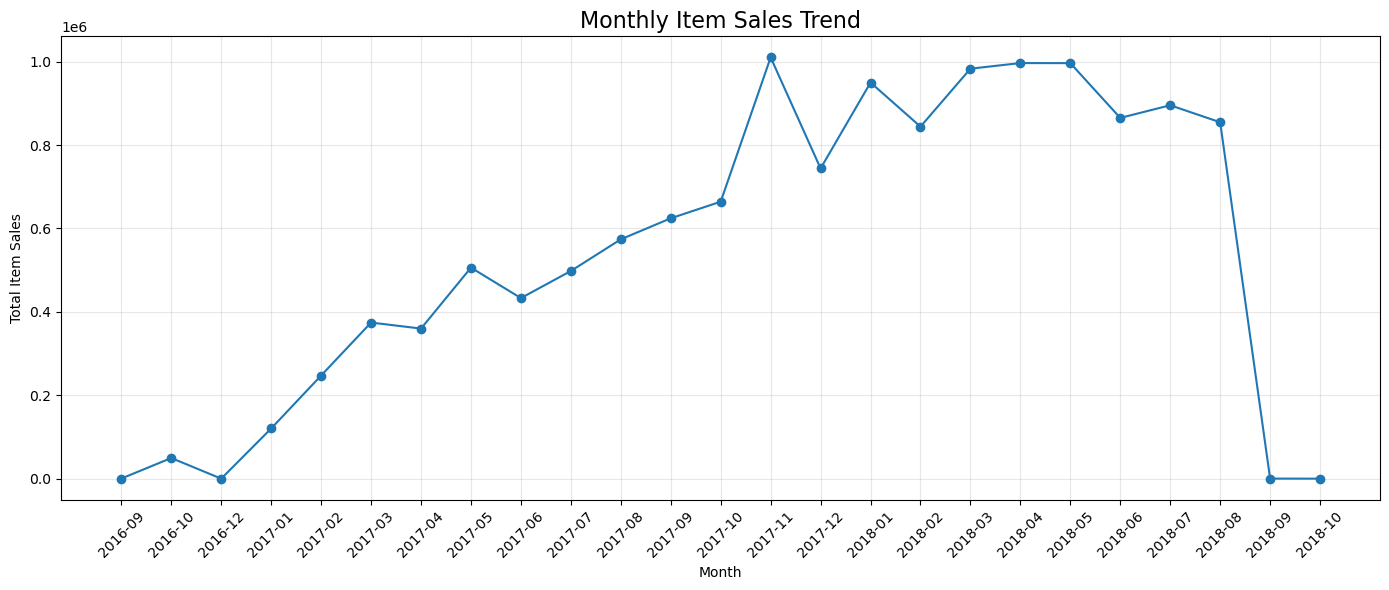

In [53]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_month"],
    monthly_sales["total_item_sales"],
    marker="o"
)

plt.title("Monthly Item Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Item Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [54]:

# Convert both month columns to the same datatype
monthly_orders["order_month"] = pd.to_datetime(
    monthly_orders["order_month"].astype(str)
)

monthly_sales["order_month"] = pd.to_datetime(
    monthly_sales["order_month"].astype(str)
)

# Verify datatypes
print("Monthly orders:", monthly_orders["order_month"].dtype)
print("Monthly sales:", monthly_sales["order_month"].dtype)

# Merge monthly data
monthly_analysis = monthly_orders.merge(
    monthly_sales,
    on="order_month",
    how="inner"
)

# Calculate average item value per order
monthly_analysis["avg_item_value_per_order"] = (
    monthly_analysis["total_item_sales"]
    / monthly_analysis["total_orders"]
)

print("\nMonthly analysis:")
display(monthly_analysis.head())

print("\nHighest average item value per order:")
display(
    monthly_analysis.nlargest(
        5, "avg_item_value_per_order"
    )
)


Monthly orders: datetime64[ns]
Monthly sales: datetime64[ns]

Monthly analysis:


,order_month,total_orders,total_item_sales,avg_item_value_per_order
0,2016-09-01,4,267.36,66.840000
1,2016-10-01,324,49507.66,152.801420
2,2016-12-01,1,10.90,10.900000
3,2017-01-01,800,120312.87,150.391087
4,2017-02-01,1780,247303.02,138.934281



Highest average item value per order:


,order_month,total_orders,total_item_sales,avg_item_value_per_order
1,2016-10-01,324,49507.66,152.801420
3,2017-01-01,800,120312.87,150.391087
6,2017-04-01,2404,359927.23,149.720146
11,2017-09-01,4285,624401.69,145.718014
19,2018-05-01,6873,996517.68,144.990205


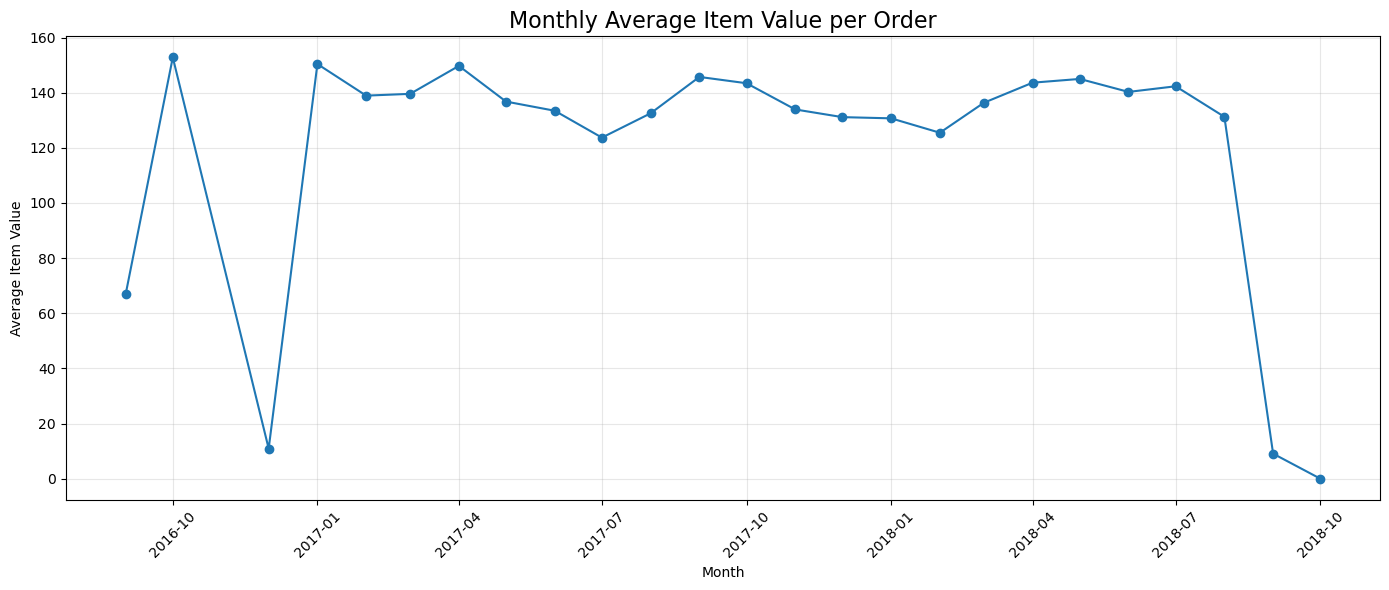

In [55]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["order_month"],
    monthly_analysis["avg_item_value_per_order"],
    marker="o"
)

plt.title("Monthly Average Item Value per Order", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Average Item Value")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [56]:

# Calculate delivery time in days
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Analyze delivered orders only
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Delivery time summary (days):")
print(
    delivered_orders["delivery_time_days"]
    .describe()
    .round(2)
)


Delivery time summary (days):
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_time_days, dtype: float64


In [57]:

longest_deliveries = (
    delivered_orders[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "delivery_time_days"
        ]
    ]
    .sort_values("delivery_time_days", ascending=False)
    .head(10)
)

display(longest_deliveries)


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,208.351759
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843


In [58]:

# Keep delivered orders with both actual and estimated dates
delivery_analysis = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

# Calculate delivery delay in days
delivery_analysis["delivery_delay_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
delivery_analysis["delivery_result"] = (
    delivery_analysis["delivery_delay_days"]
    .apply(lambda days: "Late" if days > 0 else "On time or early")
)

print("Delivery performance:")
print(delivery_analysis["delivery_result"].value_counts())

print("\nAverage delay in days:")
print(delivery_analysis["delivery_delay_days"].mean().round(2))


Delivery performance:
delivery_result
On time or early    88644
Late                 7826
Name: count, dtype: int64

Average delay in days:
-11.18


In [59]:

late_orders = delivery_analysis[
    delivery_analysis["delivery_delay_days"] > 0
]

print("Total late orders:", len(late_orders))

print("\nLate delivery delay summary (days):")
print(
    late_orders["delivery_delay_days"]
    .describe()
    .round(2)
)


Total late orders: 7826

Late delivery delay summary (days):
count    7826.00
mean        9.55
std        13.95
min         0.00
25%         1.87
50%         5.81
75%        11.82
max       188.98
Name: delivery_delay_days, dtype: float64


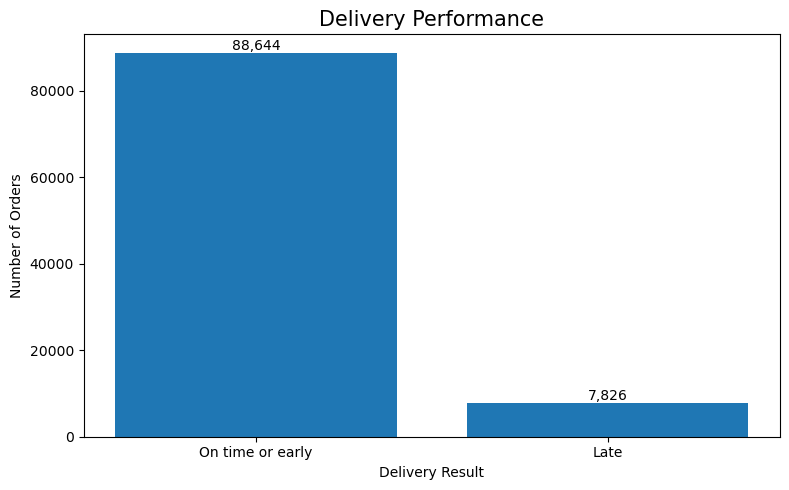

In [60]:

delivery_counts = (
    delivery_analysis["delivery_result"]
    .value_counts()
    .reindex(["On time or early", "Late"])
)

plt.figure(figsize=(8, 5))

plt.bar(
    delivery_counts.index,
    delivery_counts.values
)

plt.title("Delivery Performance", fontsize=15)
plt.xlabel("Delivery Result")
plt.ylabel("Number of Orders")

for i, value in enumerate(delivery_counts.values):
    plt.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


In [61]:



customers = dataframes["olist_customers_dataset"]

customer_orders = orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

orders_per_customer = (
    customer_orders.groupby("customer_unique_id")["order_id"]
    .nunique()
)

print("Unique customers:", orders_per_customer.size)

print("One-time customers:",
      (orders_per_customer == 1).sum())

print("Repeat customers:",
      (orders_per_customer > 1).sum())

print("\nOrders per customer:")
print(orders_per_customer.describe().round(2))


Unique customers: 96096
One-time customers: 93099
Repeat customers: 2997

Orders per customer:
count    96096.00
mean         1.03
std          0.21
min          1.00
25%          1.00
50%          1.00
75%          1.00
max         17.00
Name: order_id, dtype: float64


In [62]:

repeat_customer_frequency = (
    orders_per_customer[orders_per_customer > 1]
    .value_counts()
    .sort_index()
)

print("Orders per repeat customer:")
print(repeat_customer_frequency)

print("\nTotal repeat customers:",
      repeat_customer_frequency.sum())


Orders per repeat customer:
order_id
2     2745
3      203
4       30
5        8
6        6
7        3
9        1
17       1
Name: count, dtype: int64

Total repeat customers: 2997


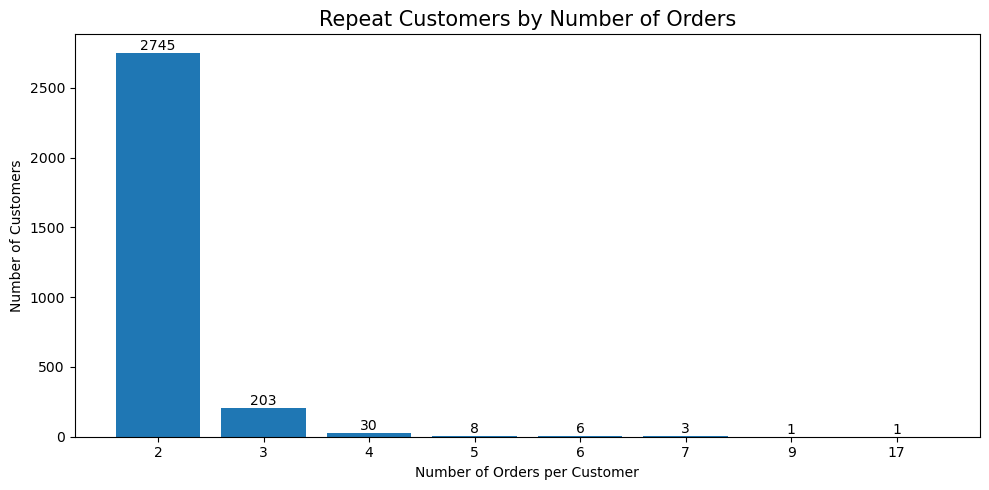

In [63]:

plt.figure(figsize=(10, 5))

plt.bar(
    repeat_customer_frequency.index.astype(str),
    repeat_customer_frequency.values
)

plt.title("Repeat Customers by Number of Orders", fontsize=15)
plt.xlabel("Number of Orders per Customer")
plt.ylabel("Number of Customers")

for i, value in enumerate(repeat_customer_frequency.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()


In [64]:

# Connect order items with customer identities
customer_items = (
    order_items
    .merge(
        orders[["order_id", "customer_id"]],
        on="order_id",
        how="left"
    )
    .merge(
        customers[["customer_id", "customer_unique_id"]],
        on="customer_id",
        how="left"
    )
)

# Calculate total item sales per unique customer
customer_value = (
    customer_items
    .groupby("customer_unique_id")
    .agg(
        total_item_spend=("price", "sum"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Show the top 10 customers by item spend
top_customers = customer_value.nlargest(
    10, "total_item_spend"
)

display(top_customers)


,customer_unique_id,total_item_spend,total_orders
3799,0a0a92112bd4c708ca5fde585afaa872,13440.0,1
81388,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2
44139,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1
82230,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1
26015,459bef486812aa25204be022145caa62,6729.0,1
95131,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1
23947,4007669dec559734d6f53e029e360987,5934.6,1
89056,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1
34820,5d0a2980b292d049061542014e8960bf,4599.9,1
27242,48e1ac109decbb87765a3eade6854098,4590.0,1


Customer spending summary:
count    95420.00
mean       142.44
std        217.66
min          0.85
25%         47.90
50%         89.90
75%        155.00
max      13440.00
Name: total_item_spend, dtype: float64


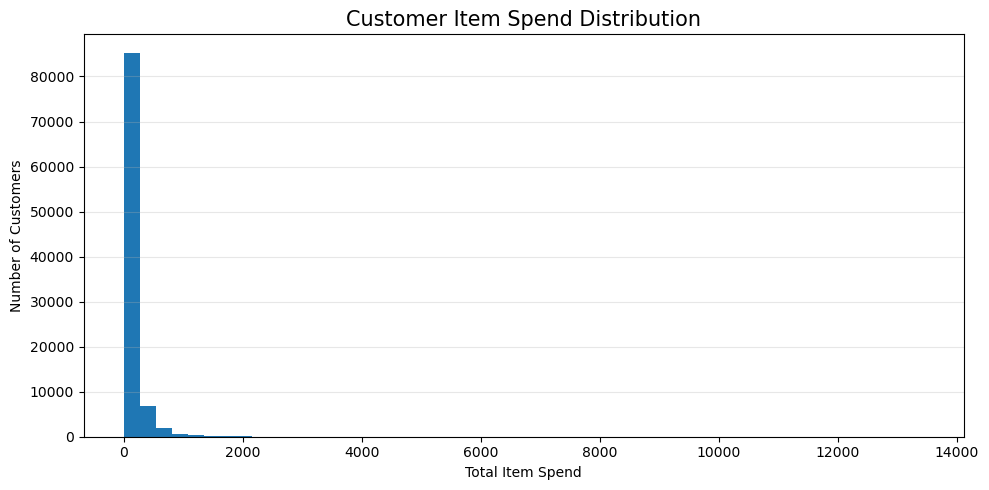

In [65]:

print("Customer spending summary:")
print(
    customer_value["total_item_spend"]
    .describe()
    .round(2)
)

plt.figure(figsize=(10, 5))

plt.hist(
    customer_value["total_item_spend"],
    bins=50
)

plt.title("Customer Item Spend Distribution", fontsize=15)
plt.xlabel("Total Item Spend")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [66]:

# Reference date: one day after the latest purchase date
reference_date = (
    orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Prepare customer-level RFM metrics
customer_rfm = (
    customer_orders
    .merge(
        order_items.groupby("order_id")["price"]
        .sum()
        .reset_index(name="order_item_spend"),
        on="order_id",
        how="left"
    )
    .groupby("customer_unique_id")
    .agg(
        last_purchase_date=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_item_spend", "sum")
    )
    .reset_index()
)

customer_rfm["recency"] = (
    reference_date - customer_rfm["last_purchase_date"]
).dt.days

print("RFM dataset shape:", customer_rfm.shape)
display(customer_rfm.head())


RFM dataset shape: (96096, 5)


,customer_unique_id,last_purchase_date,frequency,monetary,recency
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,129.90,161
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,18.90,164
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,69.00,586
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,25.99,370
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,180.00,337


In [67]:

print("RFM metrics summary:")

display(
    customer_rfm[
        ["recency", "frequency", "monetary"]
    ].describe().round(2)
)

print("\nMissing values:")
print(
    customer_rfm[
        ["recency", "frequency", "monetary"]
    ].isnull().sum()
)

print("\nZero or negative monetary values:")
print(
    (customer_rfm["monetary"] <= 0).sum()
)


RFM metrics summary:


,recency,frequency,monetary
count,96096.00,96096.00,96096.00
mean,288.74,1.03,141.44
std,153.41,0.21,217.22
min,1.00,1.00,0.00
25%,164.00,1.00,45.99
50%,269.00,1.00,89.00
75%,398.00,1.00,154.00
max,773.00,17.00,13440.00



Missing values:
recency      0
frequency    0
monetary     0
dtype: int64

Zero or negative monetary values:
676


In [68]:

# Inspect customers with zero or negative monetary values
zero_monetary_customers = customer_rfm[
    customer_rfm["monetary"] <= 0
]

print("Customers with zero/negative monetary:",
      len(zero_monetary_customers))

# Check whether these customers have order-item records
customer_order_item_check = (
    customer_orders[
        ["order_id", "customer_unique_id"]
    ]
    .drop_duplicates()
    .merge(
        order_items[["order_id"]].drop_duplicates(),
        on="order_id",
        how="left",
        indicator=True
    )
    .groupby("customer_unique_id")["_merge"]
    .apply(lambda x: (x == "both").any())
)

print("\nCustomers without any order-item records:",
      (~customer_order_item_check).sum())

print("\nZero-monetary sample:")
display(zero_monetary_customers.head())


Customers with zero/negative monetary: 676

Customers without any order-item records: 676

Zero-monetary sample:


,customer_unique_id,last_purchase_date,frequency,monetary,recency
123,004ad212c650c96c8a48f30855a7bcb8,2017-09-24 10:45:10,1,0.0,389
177,0071f46a072a9ae25bbe4438b15efe9c,2017-02-01 00:04:17,1,0.0,624
238,009b0127b727ab0ba422f6d9604487c7,2016-09-13 15:24:19,1,0.0,765
372,00f0b70fdcb8a6e1671b52a2472bd41f,2016-10-04 19:41:32,1,0.0,743
475,013b083525868a0437652ebf071cda03,2017-12-03 14:28:40,1,0.0,319


In [69]:
print(
    "Customers without order-item records:",
    (~customer_order_item_check).sum()
)

display(zero_monetary_customers.head())


Customers without order-item records: 676


,customer_unique_id,last_purchase_date,frequency,monetary,recency
123,004ad212c650c96c8a48f30855a7bcb8,2017-09-24 10:45:10,1,0.0,389
177,0071f46a072a9ae25bbe4438b15efe9c,2017-02-01 00:04:17,1,0.0,624
238,009b0127b727ab0ba422f6d9604487c7,2016-09-13 15:24:19,1,0.0,765
372,00f0b70fdcb8a6e1671b52a2472bd41f,2016-10-04 19:41:32,1,0.0,743
475,013b083525868a0437652ebf071cda03,2017-12-03 14:28:40,1,0.0,319


In [70]:

# Get orders belonging to customers without order items
zero_monetary_ids = zero_monetary_customers["customer_unique_id"]

zero_monetary_orders = customer_orders[
    customer_orders["customer_unique_id"].isin(zero_monetary_ids)
]

# Check their order statuses
print("Order status distribution:")
print(zero_monetary_orders["order_status"].value_counts())

print("\nOrder status percentages:")
print(
    (zero_monetary_orders["order_status"]
     .value_counts(normalize=True) * 100)
    .round(2)
)


Order status distribution:
order_status
unavailable    569
canceled       109
created          4
invoiced         2
shipped          1
Name: count, dtype: int64

Order status percentages:
order_status
unavailable    83.07
canceled       15.91
created         0.58
invoiced        0.29
shipped         0.15
Name: proportion, dtype: float64


In [71]:

# Keep customers with positive item spend for RFM segmentation
customer_rfm_valid = customer_rfm[
    customer_rfm["monetary"] > 0
].copy()

print("Original RFM customers:", len(customer_rfm))
print("Customers eligible for RFM:",
      len(customer_rfm_valid))
print("Excluded due to zero/negative monetary:",
      len(customer_rfm) - len(customer_rfm_valid))

print("\nRFM data check:")
display(
    customer_rfm_valid[
        ["recency", "frequency", "monetary"]
    ].describe().round(2)
)


Original RFM customers: 96096
Customers eligible for RFM: 95420
Excluded due to zero/negative monetary: 676

RFM data check:


,recency,frequency,monetary
count,95420.00,95420.00,95420.00
mean,288.10,1.03,142.44
std,153.16,0.21,217.66
min,1.00,1.00,0.85
25%,164.00,1.00,47.90
50%,269.00,1.00,89.90
75%,397.00,1.00,155.00
max,773.00,17.00,13440.00


In [72]:

customer_rfm_valid["R_score"] = pd.qcut(
    customer_rfm_valid["recency"],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

print("Recency score distribution:")
print(
    customer_rfm_valid["R_score"]
    .value_counts()
    .sort_index(ascending=False)
)

print("\nSample customer RFM scores:")
display(
    customer_rfm_valid[
        ["customer_unique_id", "recency", "R_score"]
    ].head(10)
)


Recency score distribution:
R_score
5    19131
4    19188
3    19130
2    18936
1    19035
Name: count, dtype: int64

Sample customer RFM scores:


,customer_unique_id,recency,R_score
0,0000366f3b9a7992bf8c76cfdf3221e2,161,4
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,4
2,0000f46a3911fa3c0805444483337064,586,1
3,0000f6ccb0745a6a4b88665a16c9f078,370,2
4,0004aac84e0df4da2b147fca70cf8255,337,2
5,0004bd2a26a76fe21f786e4fbd80607f,195,4
6,00050ab1314c0e55a6ca13cf7181fecf,181,4
7,00053a61a98854899e70ed204dd4bafe,232,3
8,0005e1862207bf6ccc02e4228effd9a0,592,1
9,0005ef4cd20d2893f0d9fbd94d3c0d97,220,4


In [73]:

customer_rfm_valid["F_score"] = pd.cut(
    customer_rfm_valid["frequency"],
    bins=[0, 1, 2, 3, 4, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

print("Frequency score distribution:")
print(
    customer_rfm_valid["F_score"]
    .value_counts()
    .sort_index()
)

print("\nFrequency and score mapping:")
display(
    customer_rfm_valid[
        ["frequency", "F_score"]
    ]
    .drop_duplicates()
    .sort_values("frequency")
    .head(20)
)


Frequency score distribution:
F_score
1    92431
2     2738
3      202
4       30
5       19
Name: count, dtype: int64

Frequency and score mapping:


,frequency,F_score
0,1,1
33,2,2
1093,3,3
3130,4,4
20337,5,5
7175,6,5
10354,7,5
23472,9,5
52973,17,5


In [74]:

customer_rfm_valid["M_score"] = pd.qcut(
    customer_rfm_valid["monetary"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

print("Monetary score distribution:")
print(
    customer_rfm_valid["M_score"]
    .value_counts()
    .sort_index(ascending=False)
)

print("\nMonetary value by score:")
display(
    customer_rfm_valid.groupby("M_score", observed=True)["monetary"]
    .agg(["count", "min", "median", "max"])
    .round(2)
    .sort_index(ascending=False)
)


Monetary score distribution:
M_score
5    19034
4    19051
3    17792
2    19815
1    19728
Name: count, dtype: int64

Monetary value by score:


,count,min,median,max
M_score,,,,
5,19034,179.91,284.90,13440.0
4,19051,109.95,139.00,179.9
3,17792,69.94,89.90,109.9
2,19815,39.90,54.99,69.9
1,19728,0.85,26.90,39.9


In [75]:

customer_rfm_valid["RFM_score"] = (
    customer_rfm_valid["R_score"].astype(str)
    + customer_rfm_valid["F_score"].astype(str)
    + customer_rfm_valid["M_score"].astype(str)
)

customer_rfm_valid["RFM_total"] = (
    customer_rfm_valid["R_score"]
    + customer_rfm_valid["F_score"]
    + customer_rfm_valid["M_score"]
)

print("RFM dataset shape:", customer_rfm_valid.shape)

display(
    customer_rfm_valid[
        [
            "customer_unique_id",
            "recency",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score",
            "RFM_total"
        ]
    ].head(10)
)


RFM dataset shape: (95420, 10)


,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score,RFM_total
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,129.90,4,1,4,414,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,18.90,4,1,1,411,6
2,0000f46a3911fa3c0805444483337064,586,1,69.00,1,1,2,112,4
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,25.99,2,1,1,211,4
4,0004aac84e0df4da2b147fca70cf8255,337,1,180.00,2,1,5,215,8
5,0004bd2a26a76fe21f786e4fbd80607f,195,1,154.00,4,1,4,414,9
6,00050ab1314c0e55a6ca13cf7181fecf,181,1,27.99,4,1,1,411,6
7,00053a61a98854899e70ed204dd4bafe,232,1,382.00,3,1,5,315,9
8,0005e1862207bf6ccc02e4228effd9a0,592,1,135.00,1,1,4,114,6
9,0005ef4cd20d2893f0d9fbd94d3c0d97,220,1,104.90,4,1,3,413,8


In [76]:

import numpy as np

conditions = [
    (customer_rfm_valid["R_score"] >= 4) &
    (customer_rfm_valid["F_score"] >= 3) &
    (customer_rfm_valid["M_score"] >= 4),

    (customer_rfm_valid["R_score"] >= 4) &
    (customer_rfm_valid["M_score"] >= 4),

    (customer_rfm_valid["R_score"] <= 2) &
    (customer_rfm_valid["F_score"] >= 2),

    (customer_rfm_valid["R_score"] <= 2) &
    (customer_rfm_valid["F_score"] == 1)
]

segments = [
    "Loyal High-Value",
    "Recent High-Spenders",
    "At-Risk Repeat Customers",
    "Inactive One-Time Customers"
]

customer_rfm_valid["customer_segment"] = np.select(
    conditions,
    segments,
    default="Other Customers"
)

print("Customer segment distribution:")
display(
    customer_rfm_valid["customer_segment"]
    .value_counts()
    .rename_axis("customer_segment")
    .reset_index(name="customer_count")
)


Customer segment distribution:


,customer_segment,customer_count
0,Other Customers,41653
1,Inactive One-Time Customers,36922
2,Recent High-Spenders,15669
3,At-Risk Repeat Customers,1049
4,Loyal High-Value,127


In [77]:

segment_analysis = (
    customer_rfm_valid
    .groupby("customer_segment")
    .agg(
        customer_count=("customer_unique_id", "nunique"),
        total_item_spend=("monetary", "sum"),
        avg_item_spend=("monetary", "mean"),
        median_item_spend=("monetary", "median"),
        avg_frequency=("frequency", "mean"),
        avg_recency_days=("recency", "mean")
    )
    .reset_index()
)

segment_analysis["customer_percentage"] = (
    segment_analysis["customer_count"]
    / len(customer_rfm_valid) * 100
)

segment_analysis = segment_analysis.sort_values(
    "total_item_spend", ascending=False
)

display(segment_analysis.round(2))


,customer_segment,customer_count,total_item_spend,avg_item_spend,median_item_spend,avg_frequency,avg_recency_days,customer_percentage
1,Inactive One-Time Customers,36922,5187923.07,140.51,85.00,1.00,446.28,38.69
4,Recent High-Spenders,15669,4245520.32,270.95,179.00,1.06,141.57,16.42
3,Other Customers,41653,3830608.75,91.96,62.50,1.02,199.78,43.65
0,At-Risk Repeat Customers,1049,264648.51,252.29,169.00,2.08,433.69,1.10
2,Loyal High-Value,127,62943.05,495.61,356.92,3.53,140.60,0.13


In [78]:

display(
    segment_analysis[
        [
            "customer_segment",
            "customer_count",
            "total_item_spend",
            "avg_item_spend",
            "median_item_spend",
            "avg_frequency",
            "avg_recency_days",
            "customer_percentage"
        ]
    ].to_string(index=False)
)


'           customer_segment  customer_count  total_item_spend  avg_item_spend  median_item_spend  avg_frequency  avg_recency_days  customer_percentage\nInactive One-Time Customers           36922        5187923.07      140.510348              85.00       1.000000        446.284275            38.694194\n       Recent High-Spenders           15669        4245520.32      270.950304             179.00       1.055268        141.568064            16.421086\n            Other Customers           41653        3830608.75       91.964774              62.50       1.024368        199.784721            43.652274\n   At-Risk Repeat Customers            1049         264648.51      252.286473             169.00       2.081030        433.686368             1.099350\n           Loyal High-Value             127          62943.05      495.614567             356.92       3.527559        140.598425             0.133096'

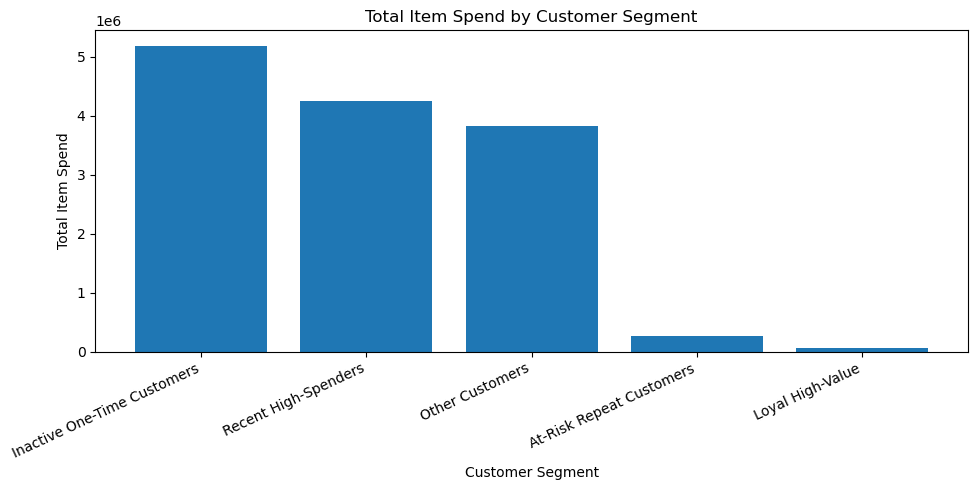

In [79]:

import matplotlib.pyplot as plt

plot_data = segment_analysis.sort_values(
    "total_item_spend", ascending=False
)

plt.figure(figsize=(10, 5))
plt.bar(
    plot_data["customer_segment"],
    plot_data["total_item_spend"]
)
plt.title("Total Item Spend by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Item Spend")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## EDA Key Findings — Olist E-Commerce Dataset

### 1. Order and Sales Trends
- Monthly order volume and total item sales were analyzed.
- The dataset contains an incomplete-looking tail in September and October 2018; these months should be treated cautiously in trend analysis and forecasting.
- Total item sales were calculated from order-item prices and exclude freight, refunds, and profit.

### 2. Delivery Performance
- The average delivery time was approximately 12.56 days.
- Around 91.9% of delivered orders arrived on or before the estimated delivery date.
- Delivery-time outliers and inconsistent timestamps were identified and should be investigated rather than automatically removed.

### 3. Customer Behavior
- The dataset contains 96,096 unique customers based on `customer_unique_id`.
- Most customers placed only one order; 2,997 customers placed multiple orders.
- Customer spending is right-skewed, meaning a small number of customers account for relatively high item spending.

### 4. RFM Analysis
- RFM analysis was performed using Recency, Frequency, and Monetary value.
- The RFM segmentation dataset contains 95,420 eligible customers.
- 676 customers with zero item spend were excluded from this segmentation dataset because no corresponding order-item records were found for them.
- Customer segments were created using explicitly defined business rules. Segment labels are analytical categories, not proof of future customer behavior.

### 5. Data Quality Decisions
- Missing review comments were retained as missing values rather than treated as errors.
- Geolocation duplicate rows were identified but not automatically deleted.
- Review-ID repetition and inconsistent order timestamps require further investigation.
- Orders without item records and payment/item total differences should be investigated before making financial conclusions.

### 6. Limitations
- Item spend is not the same as profit or net revenue.
- RFM segments describe historical behavior and do not guarantee future purchasing behavior.
- Incomplete final months may distort time-based trends.


In [80]:

print("Eligible RFM customers:", len(customer_rfm_valid))
print("Missing RFM scores:", customer_rfm_valid[
    ["R_score", "F_score", "M_score", "RFM_score", "RFM_total"]
].isna().sum().sum())
print("Missing customer segments:", customer_rfm_valid["customer_segment"].isna().sum())
print("Unique customers across segments:", customer_rfm_valid["customer_segment"].notna().sum())
print("Total segment customers:", customer_rfm_valid["customer_segment"].value_counts().sum())


Eligible RFM customers: 95420
Missing RFM scores: 0
Missing customer segments: 0
Unique customers across segments: 95420
Total segment customers: 95420


### Phase 4: MySQL Database Setup & Data Import

In [81]:
for name, df in dataframes.items():
    print(f"\n{name}")
    print(df.columns.tolist())


olist_customers_dataset
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

olist_orders_dataset
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'carrier_purchase_diff_hours', 'delivery_carrier_diff_hours']

olist_order_items_dataset
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

olist_order_payments_dataset
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

olist_order_reviews_dataset
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

olist_products_dataset
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_leng

In [84]:
import mysql.connector

In [ ]:
C:\Users\Dm692\OneDrive\Desktop\DataAnalyst\project\Python, PowerBi, SQL project\data\raw

### Phase 4: MySQL Database Setup & Data Import

**Status:** COMPLETED

All 9 Olist CSV datasets have been imported into the `olist_ecommerce` MySQL database and their row counts have been verified.

**Important:** Do not rerun the import cells unless the tables have been intentionally cleared or the import process is being performed on a fresh database.

November 2017 mein 7,451 orders aur 1,010,271.37 item sales hui — tumhare shared results mein sabse zyada.



January 2018 mein 7,220 orders aur 950,030.36 item sales hui.



March 2018 mein 7,188 orders aur 983,213.44 item sales hui.



September 2016 aur December 2016 jaise initial months mein bahut kam orders hain. Dataset ke shuruati aur aakhri months ko incomplete data ki wajah se carefully interpret karna chahiye.



Ye sales product prices ka total hai; freight charges aur profit include nahi hain.